# 📊 Notebook 1: Data Exploration & Visualization
**Project**: Sentiment Analysis on YouTube Comments  
**Dataset**: Amaan Poonawala YouTube Comments Sentiment Dataset  
**Objective**: Perform thorough Exploratory Data Analysis (EDA) on pre-cleaned YouTube comments, analyze sentiment distributions, examine comment length distributions, generate word clouds, and visualize top unigrams/bigrams.


In [1]:
# Standard imports for data manipulation and visualization
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

# Configure plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
print("Libraries successfully imported!")


Libraries successfully imported!


---
## 1. Data Loading & Integrity Checks
We check whether the dataset exists in the default Kaggle path or local directory, load it into a pandas DataFrame, and perform null check operations.


In [2]:
# Dataset Path Handling (Kaggle vs Local Environment)
KAGGLE_PATH = "/kaggle/input/datasets/amaanpoonawala/youtube-comments-sentiment-dataset/youtube_comments_cleaned.csv"
LOCAL_PATH = "youtube_comments_cleaned.csv"

data_path = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
print(f"Loading dataset from: {data_path}")

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape}")
print("\nDataset Summary:")
df.info()

# Handle Null / Missing Values
print("\nMissing values before cleaning:")
print(df[['CommentText', 'Sentiment']].isnull().sum())

df = df.dropna(subset=['CommentText', 'Sentiment']).reset_index(drop=True)
df['CommentText'] = df['CommentText'].astype(str)

print("\nMissing values after cleaning:")
print(df[['CommentText', 'Sentiment']].isnull().sum())
print(f"Cleaned Dataset Shape: {df.shape}")
df[['CommentText', 'Sentiment']].head()


Loading dataset from: /kaggle/input/datasets/amaanpoonawala/youtube-comments-sentiment-dataset/youtube_comments_cleaned.csv
Dataset Shape: (1032225, 12)

Dataset Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1032225 entries, 0 to 1032224
Data columns (total 12 columns):
 #   Column           Non-Null Count    Dtype 
---  ------           --------------    ----- 
 0   CommentID        1032225 non-null  object
 1   VideoID          1032225 non-null  object
 2   VideoTitle       1032225 non-null  object
 3   AuthorName       1031594 non-null  object
 4   AuthorChannelID  1032225 non-null  object
 5   CommentText      1032225 non-null  object
 6   Sentiment        1032225 non-null  object
 7   Likes            1032225 non-null  int64 
 8   Replies          1032225 non-null  int64 
 9   PublishedAt      1032225 non-null  object
 10  CountryCode      1032225 non-null  object
 11  CategoryID       1032225 non-null  int64 
dtypes: int64(3), object(9)
memory usage: 94.5+ MB

Missin

,CommentText,Sentiment
0,Anyone know what movie this is?,Neutral
1,The fact they're holding each other back while...,Positive
2,waiting next video will be?,Neutral
3,Thanks for the great video.\n\nI don't underst...,Neutral
4,Good person helping good people.\nThis is how ...,Positive


---
## 2. Sentiment Class Distribution Analysis
Visualizing the target variable (`Sentiment`) class breakdown using a styled Seaborn countplot.


/tmp/ipykernel_48/3148174039.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


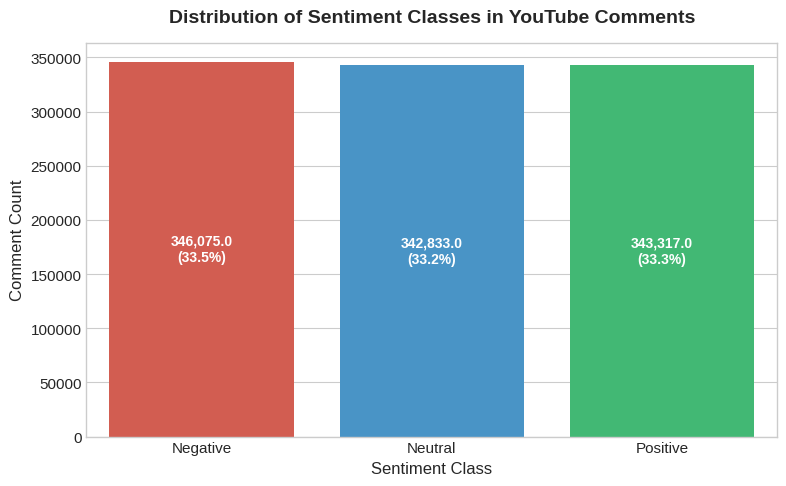

In [3]:
# Plotting Class Distribution
plt.figure(figsize=(8, 5))
palette = {"Positive": "#2ecc71", "Neutral": "#3498db", "Negative": "#e74c3c"}

ax = sns.countplot(
    data=df, 
    x='Sentiment', 
    palette=palette, 
    order=['Negative', 'Neutral', 'Positive']
)

plt.title('Distribution of Sentiment Classes in YouTube Comments', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Sentiment Class', fontsize=12)
plt.ylabel('Comment Count', fontsize=12)

# Annotate bars with exact counts and percentages
total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = f'{100 * height / total:.1f}%'
    ax.annotate(f'{height:,}\n({percentage})',
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=10, color='white', fontweight='bold')

plt.tight_layout()
plt.show()


---
## 3. Comment Length Analysis
Computing character lengths and word counts per comment, and visualizing distributions across sentiment classes using boxplots and histograms.


Summary Statistics of Comment Lengths:
        char_length    word_count
count  1.032225e+06  1.032225e+06
mean   1.071201e+02  1.920645e+01
std    1.782266e+02  3.005995e+01
min    1.000000e+00  0.000000e+00
25%    3.400000e+01  6.000000e+00
50%    6.500000e+01  1.200000e+01
75%    1.210000e+02  2.200000e+01
max    9.997000e+03  1.796000e+03


/tmp/ipykernel_48/909783924.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


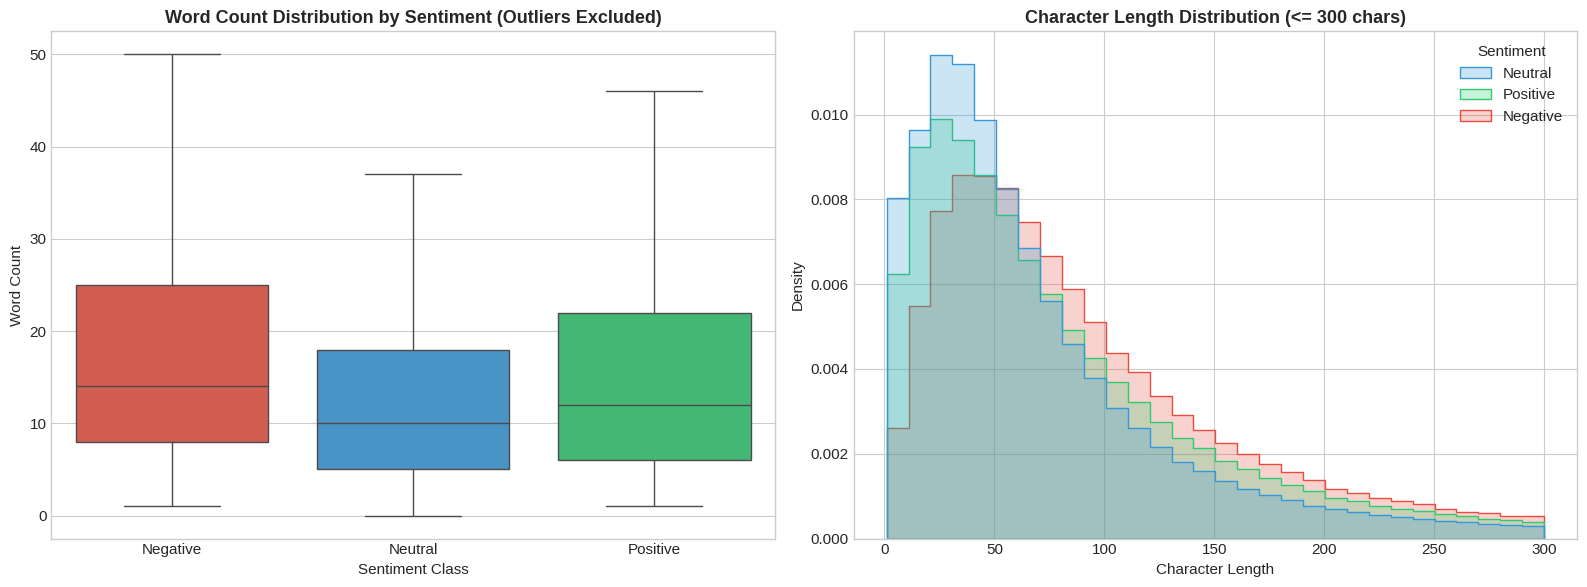

In [4]:
# Compute length metrics
df['char_length'] = df['CommentText'].apply(len)
df['word_count'] = df['CommentText'].apply(lambda x: len(x.split()))

print("Summary Statistics of Comment Lengths:")
print(df[['char_length', 'word_count']].describe())

# Visualizing Length Distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot for Word Counts per Sentiment
sns.boxplot(
    data=df, 
    x='Sentiment', 
    y='word_count', 
    palette=palette, 
    order=['Negative', 'Neutral', 'Positive'], 
    ax=axes[0],
    showfliers=False
)
axes[0].set_title('Word Count Distribution by Sentiment (Outliers Excluded)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sentiment Class')
axes[0].set_ylabel('Word Count')

# Histogram/KDE for Character Lengths
sns.histplot(
    data=df[df['char_length'] <= 300], 
    x='char_length', 
    hue='Sentiment', 
    palette=palette, 
    element='step', 
    stat='density', 
    common_norm=False, 
    ax=axes[1],
    bins=30
)
axes[1].set_title('Character Length Distribution (<= 300 chars)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Character Length')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()


---
## 4. Word Cloud Generation (Positive vs Negative vs Neutral)
Generating Word Clouds to visually analyze prominent words across different sentiments.


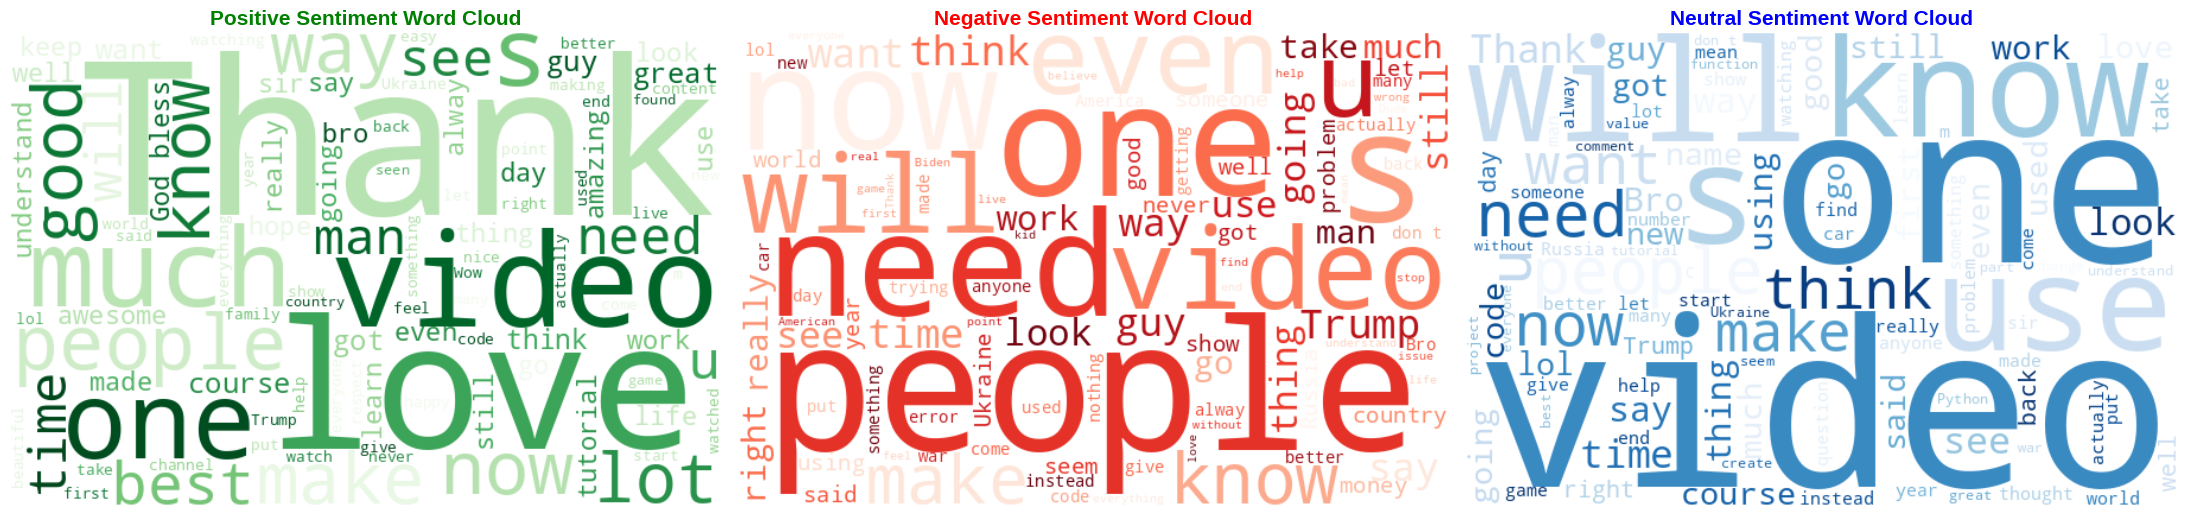

In [5]:
# Extract text by sentiment category
pos_text = " ".join(df[df['Sentiment'] == 'Positive']['CommentText'])
neg_text = " ".join(df[df['Sentiment'] == 'Negative']['CommentText'])
neu_text = " ".join(df[df['Sentiment'] == 'Neutral']['CommentText'])

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# WordCloud for Positive
wc_pos = WordCloud(width=600, height=400, background_color='white', colormap='Greens', max_words=100).generate(pos_text)
axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].set_title('Positive Sentiment Word Cloud', fontsize=15, fontweight='bold', color='green')
axes[0].axis('off')

# WordCloud for Negative
wc_neg = WordCloud(width=600, height=400, background_color='white', colormap='Reds', max_words=100).generate(neg_text)
axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].set_title('Negative Sentiment Word Cloud', fontsize=15, fontweight='bold', color='red')
axes[1].axis('off')

# WordCloud for Neutral
wc_neu = WordCloud(width=600, height=400, background_color='white', colormap='Blues', max_words=100).generate(neu_text)
axes[2].imshow(wc_neu, interpolation='bilinear')
axes[2].set_title('Neutral Sentiment Word Cloud', fontsize=15, fontweight='bold', color='blue')
axes[2].axis('off')

plt.tight_layout()
plt.show()


---
## 5. Top Unigram and Bigram Frequency Analysis
Extracting and visualizing the top 20 most frequent unigrams and bigrams using scikit-learn's `CountVectorizer`.


/tmp/ipykernel_48/619516227.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ngram_df, y='Ngram', x='Frequency', palette='mako')


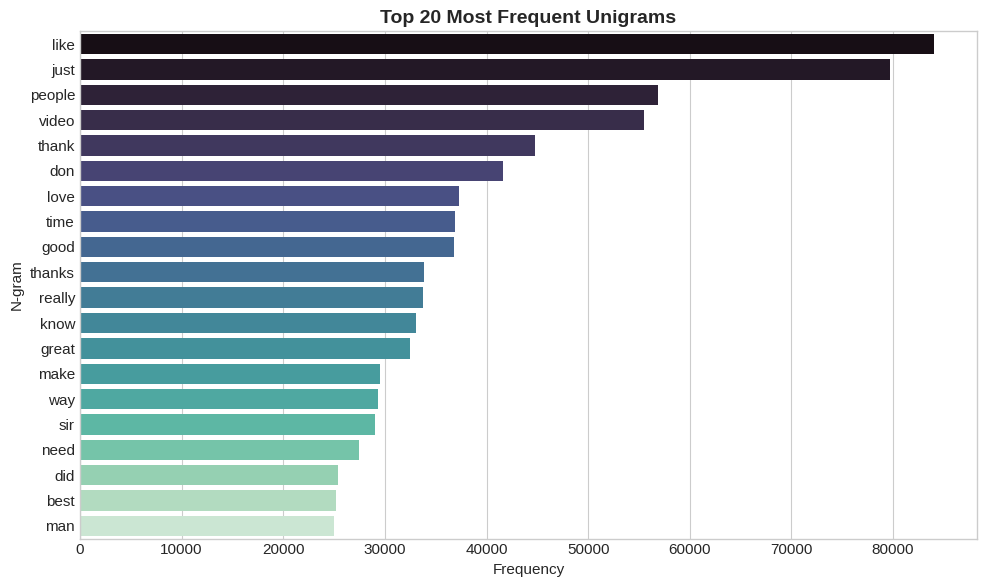

/tmp/ipykernel_48/619516227.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ngram_df, y='Ngram', x='Frequency', palette='mako')


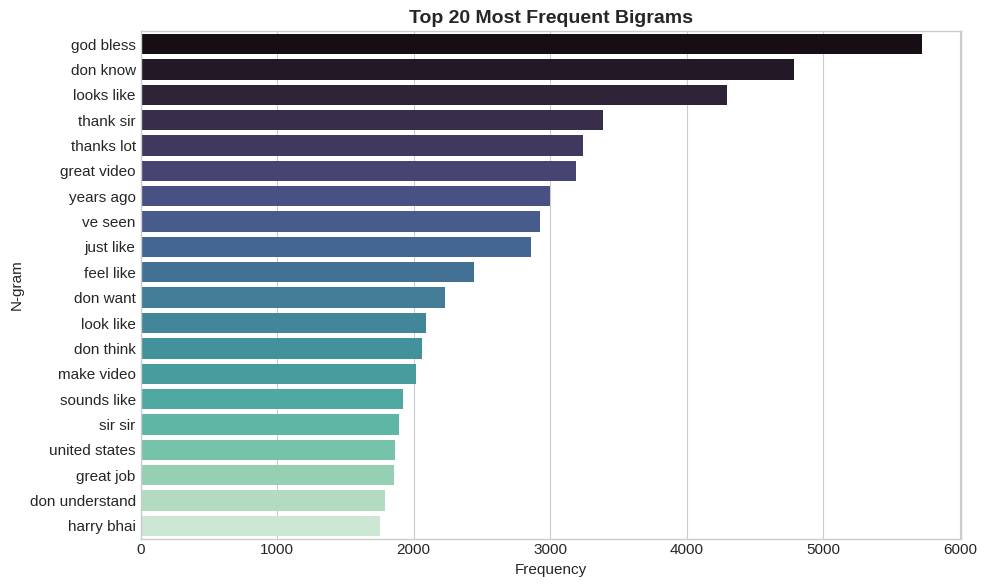

In [6]:
def plot_top_ngrams(corpus, ngram_range=(1, 1), top_n=20, title='Top N-grams'):
    vec = CountVectorizer(ngram_range=ngram_range, stop_words='english').fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)[:top_n]
    
    ngram_df = pd.DataFrame(words_freq, columns=['Ngram', 'Frequency'])
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=ngram_df, y='Ngram', x='Frequency', palette='mako')
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel('Frequency')
    plt.ylabel('N-gram')
    plt.tight_layout()
    plt.show()

# Plot Top 20 Unigrams
plot_top_ngrams(df['CommentText'], ngram_range=(1, 1), top_n=20, title='Top 20 Most Frequent Unigrams')

# Plot Top 20 Bigrams
plot_top_ngrams(df['CommentText'], ngram_range=(2, 2), top_n=20, title='Top 20 Most Frequent Bigrams')


---
## 6. Key Takeaways & Observations
1. **Class Balance**: Observations regarding the relative frequency of Positive, Neutral, and Negative comments.
2. **Comment Lengths**: Distribution indicates the typical comment span; neutral comments often differ in word count compared to emotional polar comments.
3. **Vocabulary Patterns**: Word clouds and n-gram analyses reveal clean features for downstream TF-IDF and deep learning models.
